# 🌳 Trees, Gini and more!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** accuracy of your machine learning model.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell.

## 🧪 A note on test data

In a departure from real-world scenarios, you will have access to the target variables of the test sets for each task. This has been arranged to facilitate the evaluation of your models. However, remember that in actual machine learning projects, test targets are not available, as predicting these is the ultimate goal of your supervised models.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences are enough; there is no length requirement.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Some questions and tasks are a bit vague. You are expected to apply techniques we learned in the lectures.
- Submit this notebook to Canvas. Deliver the notebook with its outputs saved; ideally, *restart* the kernel and then *run all*.

Good luck!

---

# 🌴 Problem 1: Fit a decision tree classifier!

### ❗️ The problem
In this first problem, you must load the data and train a decision tree classifier on the provided dataset!

### 📋 Formal requirements
1. **Implementation**:
   - Load `problem1.csv`
   - Analyse the dataset (e.g. the class distribution)
   - Preprocess the training data
   - Train a decision tree classifier
   - Implement the metrics presented in the lectures
2. **Performance**: Achieve at least **0.90** classification accuracy on the test set
3. **Discussion**:
   - What preprocessing do we need to apply before training, and why?
   - Do we need to scale the features?
   - What do you observe in the decision boundary plot before and after preprocessing?
   - What happens when you increase or decrease the depth of the tree?

In [133]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("problem1.csv")

train = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

y_train = train["y"]
y_test = test["y"]

In [135]:
# ====================================
# YOUR CODE GOES HERE: load the data from the problem1.csv file
# ====================================
df = pd.read_csv("problem1.csv")

train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

In [136]:
# X_train = train[['x0', 'x1']]
# y_train = train['y']
# X_test = test[['x0', 'x1']]
# y_test = test['y']


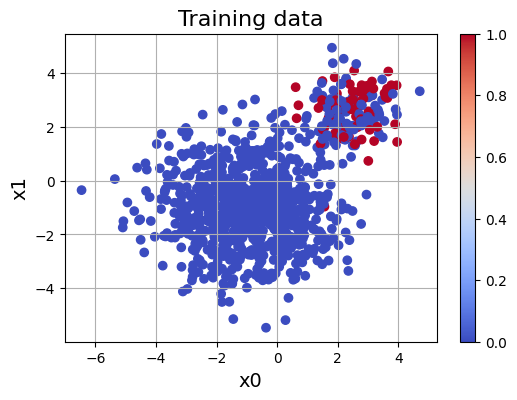

In [137]:
# ====================================
# YOUR CODE GOES HERE: let's analyse the dataset
# ====================================

# ====================================
plt.figure(figsize=(6, 4))
plt.scatter(train['x0'], train['x1'], c=train['y'], cmap='coolwarm')
plt.grid(True)
plt.xlabel('x0', fontsize=14)
plt.ylabel('x1', fontsize=14)
plt.title('Training data', fontsize=16)
plt.colorbar()
plt.show()

## Analyzing training data

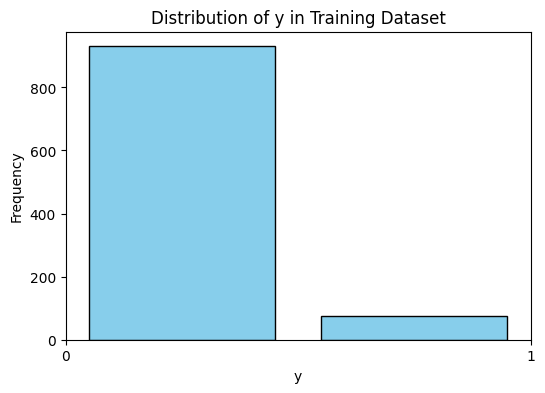

Proportion of class 1 in training dataset: 0.08


In [138]:
plt.figure(figsize=(6, 4))
plt.hist(y_train, bins= 2, rwidth=0.8, color='skyblue', edgecolor='black')
plt.xticks([0, 1])
plt.xlabel('y')
plt.ylabel('Frequency')
plt.title('Distribution of y in Training Dataset')
plt.show()

class_1_share = train["y"].sum()/len(train)
print(f"Proportion of class 1 in training dataset: {class_1_share:.2f}")

We notice that only about 8 % of the datapoints belong to class 1. If we assume the same distribution for the testing dataset,
and we only require 90 % classification accuray, then we could predict that all datapoints belong to class 0, 
but we won't (for the love of the game).

## Info about training data

In [139]:
print(train.info())
print(train[["x0", "x1", "y"]].isnull().sum())
print(train["y"].value_counts())
print(train["y"].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
Index: 1006 entries, 0 to 1005
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x0      1006 non-null   float64
 1   x1      1006 non-null   float64
 2   y       1006 non-null   float64
 3   split   1006 non-null   object 
dtypes: float64(3), object(1)
memory usage: 39.3+ KB
None
x0    0
x1    0
y     0
dtype: int64
y
0.0    930
1.0     76
Name: count, dtype: int64
y
0.0    0.924453
1.0    0.075547
Name: proportion, dtype: float64


## Addingg possible features

In [140]:
def add_features(data):
    result = data[["x0", "x1"]].copy()

    result["sum"] = result["x0"] + result["x1"]
    result["difference"] = result["x0"] - result["x1"]
    result["radius"] = np.sqrt(
        result["x0"]**2 + result["x1"]**2
    )

    return result


X_train_all = add_features(train)
X_test_all = add_features(test)

print(X_train_all.head())

         x0        x1       sum  difference    radius
0  1.469311 -0.816098  0.653213    2.285408  1.680741
1  1.558715 -0.966211  0.592503    2.524926  1.833891
2  0.063461  0.206364  0.269825   -0.142902  0.215901
3  0.025497  0.326340  0.351838   -0.300843  0.327335
4  0.130497  0.456340  0.586838   -0.325843  0.474632


## Only baseline features

In [141]:
baseline_features = ["x0", "x1"]

X_train_baseline = X_train_all[baseline_features]
X_test_baseline = X_test_all[baseline_features]

baseline_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42, # For reproducibility. Same as set_seed in R.
    # class_weight="balanced",
)


baseline_model.fit(X_train_baseline, y_train)

baseline_prediction = baseline_model.predict(X_test_baseline)

print("Baseline accuracy:",
      accuracy_score(y_test, baseline_prediction))
print("Confusion matrix:")
print(confusion_matrix(y_test, baseline_prediction))

Baseline accuracy: 0.5866666666666667
Confusion matrix:
[[148   2]
 [122  28]]


## Cross-validation with different depths and number of features

In [142]:
feature_sets = {
    "x0, x1": ["x0", "x1"],
    "sum": ["sum"],
    "x0, x1, sum": ["x0", "x1", "sum"],
    "sum, difference": ["sum", "difference"],
    "all features": [
        "x0",
        "x1",
        "sum",
        "difference",
        "radius"
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42 # For reproducibility. Same as set_seed(42) in R.
)

results = []

for name, features in feature_sets.items():
    for depth in [1, 2, 3, 4, 5, 8, 12]:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=3,
            random_state=42
        )

        scores = cross_val_score(
            model,
            X_train_all[features],
            y_train,
            cv=cv,
            scoring="accuracy"
        )

        results.append({
            "features": name,
            "depth": depth,
            "cv_accuracy_mean": scores.mean(),
            "cv_accuracy_std": scores.std()
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "cv_accuracy_mean",
    ascending=False
)

results_df.head(10)

,features,depth,cv_accuracy_mean,cv_accuracy_std
8,sum,2,0.928432,0.003927
9,sum,3,0.925447,0.008326
33,all features,8,0.924462,0.013806
21,"sum, difference",1,0.924457,0.001832
28,all features,1,0.924457,0.001832
0,"x0, x1",1,0.924457,0.001832
7,sum,1,0.924457,0.001832
14,"x0, x1, sum",1,0.924457,0.001832
26,"sum, difference",8,0.923472,0.010133
18,"x0, x1, sum",5,0.923447,0.012087


In [143]:
results_simple = results_df[results_df["features"] == "x0, x1"]
results_simple

,features,depth,cv_accuracy_mean,cv_accuracy_std
0,"x0, x1",1,0.924457,0.001832
4,"x0, x1",5,0.921526,0.028823
1,"x0, x1",2,0.916497,0.015564
3,"x0, x1",4,0.915512,0.009394
2,"x0, x1",3,0.912531,0.010657
6,"x0, x1",12,0.911546,0.015114
5,"x0, x1",8,0.905591,0.018458


Notice that simple models work equally well as more complex models. On cv-mean on training-data

## What if we use class_weight="balanced" in the baseline model?

In [144]:
features = ["x0", "x1"]

for class_weight in [None, "balanced"]:
    model = DecisionTreeClassifier(
        max_depth=1,
        min_samples_leaf=3,
        class_weight=class_weight,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train_all[features],
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    print(
        f"class_weight={class_weight}, "
        f"CV accuracy={scores.mean():.3f}"
    )

class_weight=None, CV accuracy=0.924
class_weight=balanced, CV accuracy=0.878


This might suggest that if the disribution of classes in the test-dataset is more even, we should use class_weight is balanced

## Trying a final model based on insight from training and cross-validation 

In [145]:
selected_features = ["x0", "x1"]
selected_depth = 3
selected_weight = "balanced"

In [146]:
final_model = DecisionTreeClassifier(
    max_depth=selected_depth,
    min_samples_leaf=3,
    class_weight=selected_weight,
    random_state=42
)

final_model.fit(
    X_train_all[selected_features],
    y_train
)

final_prediction = final_model.predict(
    X_test_all[selected_features]
)

In [147]:
print("Test accuracy:",
      accuracy_score(y_test, final_prediction))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, final_prediction))

print("\nClassification report:")
print(classification_report(
    y_test,
    final_prediction,
    zero_division=0
))

Test accuracy: 0.91

Confusion matrix:
[[125  25]
 [  2 148]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.98      0.83      0.90       150
         1.0       0.86      0.99      0.92       150

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.91       300
weighted avg       0.92      0.91      0.91       300



## Ivestigating different metrics as argument to model

In [148]:
df = pd.read_csv("problem1.csv")

train = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

print(train.columns)

Index(['x0', 'x1', 'y', 'split'], dtype='object')


In [149]:
features = ["x0", "x1"]

X_train = train[features]
y_train = train["y"]

criteria = ["gini", "entropy", "log_loss"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

criterion_results = []

for criterion in criteria:
    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=2,
        min_samples_leaf=3,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    criterion_results.append({
        "criterion": criterion,
        "mean_accuracy": scores.mean(),
        "std_accuracy": scores.std()
    })

results_df = pd.DataFrame(criterion_results)
print(results_df)

  criterion  mean_accuracy  std_accuracy
0      gini       0.916497      0.015564
1   entropy       0.924457      0.001832
2  log_loss       0.924457      0.001832


We notice that on validation-data, gini-impurity actually seems like the worst metric to use as loss in the training process. But this was with different combinations of other parameters.

### ❓ What preprocessing do we need to apply before training, and why?


### Answer
I actually ended up doig no preprocessing. I have understood that the process of preprocessing is

- Scale features if necessary
- Handle missing variables by either inserting a value or removing the datapoint 
- Encode categorical covariates/features. 

So I suppose my answer is that no preprocessing is needed. There are no missing values, no categorical covariates and scaling is not necessary.

### ❓ Do we need to scale the features?

### Answer
No, we do not need to scale the features. Scaling is often necessary in Generalized Linear Models, GLM's, (that we used in the previous assignment), 
but not so  much in tree-based models. The reason for that is that we have splitting criterions such as 
$x_0 < \alpha$, and the scale of $x_0$ does not have the samme effect for those types of decisions as for GLM's

In [150]:
clf = final_model

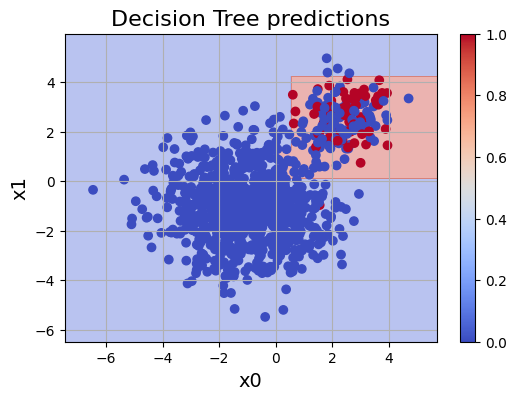

In [151]:
# visualize the decision boundary
x0_min, x0_max = train['x0'].min() - 1, train['x0'].max() + 1
x1_min, x1_max = train['x1'].min() - 1, train['x1'].max() + 1
xx0, xx1 = np.meshgrid(np.arange(x0_min, x0_max, 0.01),
                       np.arange(x1_min, x1_max, 0.01))

grid = pd.DataFrame({'x0': xx0.ravel(), 'x1': xx1.ravel()})
Z = clf.predict(grid)
Z = Z.reshape(xx0.shape)

plt.figure(figsize=(6, 4))
plt.contourf(xx0, xx1, Z, alpha=0.4, cmap='coolwarm')
plt.scatter(train['x0'], train['x1'], c=y_train, cmap='coolwarm')
plt.grid(True)
plt.xlabel('x0', fontsize=14)
plt.ylabel('x1', fontsize=14)
plt.title('Decision Tree predictions', fontsize=16)
plt.colorbar()
plt.show()

### ❓ What do you observe in the decision boundary plot before and after preprocessing?


I did no preprocessing. See why in answer to previous questions. 

### ❓ What happens when you increase or decrease the depth of the tree?


When we increase or decrease the trees, we have regions that define classes with more complex shapes. In the plot above, I have max_depth = 3. 
If we had max_depth = 2, I believe we woyld just have a red rectangle among a larger blue area. Increasing the depth of the tree
gives a more complex and flexible model, which might result in overfitting. In the context of MSE, increasin depth usually gives 
lower bias and larger variance, though we do not use MSE as loss-function here.

# 🌴🌴 Problem 2: Predict Viking voyage survivors 🗡️
### ❗️ The problem
You are given a dataset with information about the passengers on Viking voyages.
Your task is to develop a decision tree classifier that predicts which Vikings **survived** a **voyage**.

### 📋 Formal requirements
1. **Implementation**:
   - Do a simple data analysis
   - Preprocess the data 
   - Train a decision tree classifier
   - Report the cross-validation score and the test accuracy
   - Try different split criteria for the decision tree
   - Plot the decision tree
   - Use a boosting technique to improve the accuracy!
   - Use Naïve Bayes to predict whether a single new voyager survives
2. **Performance**: Achieve at least **0.80** classification accuracy on the test set
3. **Discussion**:
   - Analyse the dataset. Are there any features that already predict survival better than a random guess?
   - What is the purpose of cross-validation?
   - Which split criterion do you prefer, and why?
   - What is Gini impurity? Use an example from the decision tree graph you created
   - Which terms of Bayes theorem can you estimate from this dataset, and which ones are difficult?
   - Use Naïve Bayes: does the new voyager have a higher or lower chance of surviving?

In [152]:
df = pd.read_csv('problem2.csv')
print(len(df))

500


## Splitting data into training data and testing data, as well as X and y

In [160]:
# 400 random unique numbers from 0 to 500 (length of dataset)
random_indices = np.random.choice(df.index, size=400, replace=False)

train = df.loc[random_indices]
print(len(train))

test = df.drop(random_indices)
print(len(test))

400
100


In [154]:
train.head()

,passenger_id,name,sex,age,role,ship,destination,clan_origin,armor,provisions_kg,family_aboard,prior_voyages,survived
146,147,Sigurd Ragnarsson,Male,42.0,Karl,Drakvinge,Normandy,Nidaros,NaN,16.2,0,4,0
28,29,Knut Ulfsson,Male,23.0,Karl,Sjøulven,Vinland,Nidaros,NaN,17.1,0,0,0
79,80,Sigurd Torsteinsson,Male,42.0,Karl,Ormen Lange,Miklagard,Nidaros,NaN,81.7,0,0,0
435,436,Håkon Bjørnsson,Male,8.0,Karl,Sjøulven,Miklagard,Kaupang,NaN,2.0,1,0,0
464,465,Runa Ketilsdóttir,Female,26.0,Thrall,Drakvinge,Lindisfarne,Kaupang,NaN,10.0,3,0,1


In [155]:
X_train = train.drop(columns = ["survived"])
y_train = train["survived"]

X_test = test.drop(columns = ["survived"])
y_test = test["survived"]

## Overview of categorical covariates

In [159]:
feature = "sex" # Switch this to investigate other features
train[feature].value_counts()

sex
Male      293
Female    107
Name: count, dtype: int64

## Histogram of numerical covariates

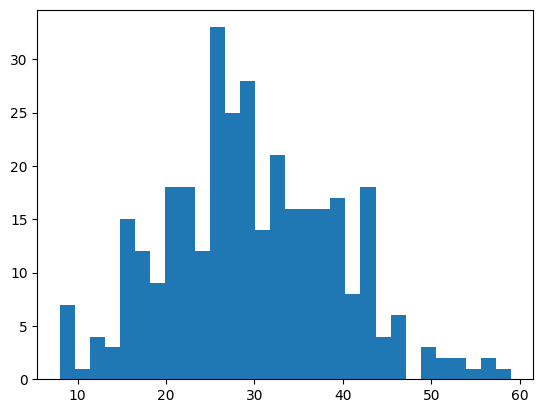

In [157]:
feature = "age"
plt.hist(train[feature], bins = 30)
plt.show()

## Preprocessing

### Removing name. This is "picked up" in passenger_id

In [158]:

if "name" in X_train.columns:
    X_train = X_train.drop(columns = ["name"])

if "name" in X_test.columns:  
    X_test = X_test.drop(columns = ["name"])


### Let's start by understanding the dataset.

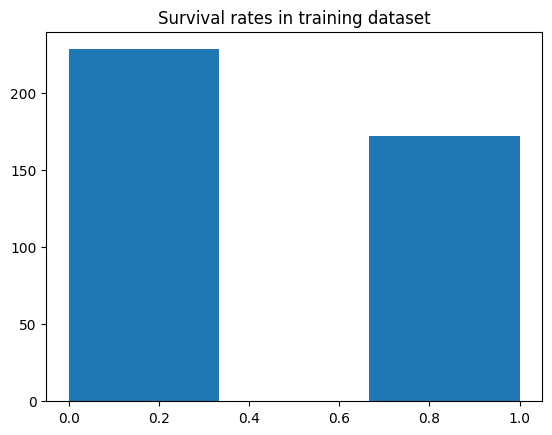

Total number of suvived = 172
Length of dataset: 400


0.43

In [187]:
plt.hist(train["survived"], bins = 3)
plt.title("Survival rates in training dataset")
plt.show()
print(f"Total number of suvived = {train["survived"].sum()}")
print(f"Length of dataset: {len(train)}")

172/400

In [170]:

train_male = train[train["sex"] == "Male"]
train_female = train[train["sex"] == "Female"]

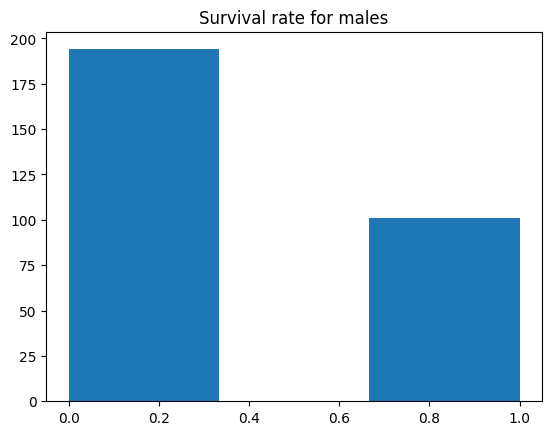

In [172]:
plt.hist(train_male["survived"], bins = 3)
plt.title("Survival rate for males")
plt.show()

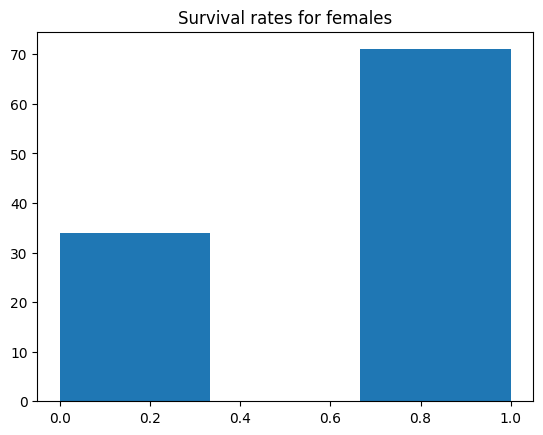

In [174]:
plt.hist(train_female["survived"], bins = 3)
plt.title("Survival rates for females")
plt.show()

In [178]:
# Let's analyse the dataset
# Make some comments about what you print and what useful information it gives
# ====================================
# YOUR CODE GOES HERE: Let's analyse the dataset!
# ====================================


rate_male = train_male["survived"].mean()
rate_female = train_female["survived"].mean()
rate_total = train["survived"].mean()

# ====================================
print(f"Female survival rate: {rate_female:.1%}")
print(f"Male survival rate: {rate_male:.1%}")
print(f"Total survival rate on training dataset: {rate_total:.1%}")

Female survival rate: 67.6%
Male survival rate: 34.2%
Total survival rate on training dataset: 43.0%


### ❓ Are there any features that already predict survival better than a random guess?


In [183]:
men = 293
women = 107

total = men + women 

accuracy_one_split = rate_female * (women/total) + (1- rate_male) * (men/total)
print(accuracy_one_split)

0.6625928167877321


### Answer
From what we now know abot survival in males vs females. It seems we would get better predictions if we have just one split in the tree,
which is sex == "Female", and then predict survived = 1 for females, and 0 for males. We would then have an accuracy as in result from cell above. If we just predicted survival == 1 for all datapoints in train, we would have a prediction accuracy of about 57 % (see output from two cells above).

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
target = 'survived'
# ====================================
# YOUR CODE GOES HERE: Train the model:)
# ====================================

# ====================================
print(f"CV Accuracy: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
print(f"Test accuracy: {a:.4f}")

### ❓ What is the purpose of cross validation?


In [ ]:
# Compare the different split criteria
# ====================================
# YOUR CODE GOES HERE: try the different split criteria (gini, entropy, log_loss)
# and report the cross-validation and test accuracy for each
# ====================================


### ❓ Try different DecisionTreeClassifier criteria, report what accuracy you get. Which criterion do you prefer?


In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# ====================================
# YOUR CODE GOES HERE: Plot the decision tree nodes!
# ====================================


### ❓ What is Gini? Use an example from the decision tree graph you created.


## Improving the results with boosting 🚀

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
# ====================================
# YOUR CODE GOES HERE: Use AdaBoostClassifier to get even better results!
# ====================================

# ====================================
ada_acc = accuracy_score(y_test, y_pred_ada)
print(f"AdaBoost CV Accuracy: {ada_cv_scores.mean():.3f} ± {ada_cv_scores.std():.3f}")
print(f"AdaBoost test accuracy: {ada_acc:.4f}")

### ❓ Try estimating the factors of Bayes theorem using this dataset. What terms can you estimate and which ones are difficult and why?
$$P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}$$

In [ ]:
# ====================================
# YOUR CODE GOES HERE: estimate the terms of Bayes theorem you can
# ====================================


### ❓ Use Naïve Bayes. Does Endre have a higher or lower chance of surviving than dying on a voyage?

A voyager named **Endre** is about to set sail. This is what we know about him:

| Feature | Value |
| --- | --- |
| `sex` | Male |
| `age` | 25 |
| `role` | Hirdman |
| `ship` | Drakvinge |
| `destination` | Normandy |
| `clan_origin` | Nidaros |
| `armor` | Chainmail |
| `provisions_kg` | 49 |
| `family_aboard` | 2 |
| `prior_voyages` | 12 |

Does he have a **higher or lower** chance of surviving the voyage?

In [ ]:
# ====================================
# YOUR CODE GOES HERE: Naïve Bayes
# You can either do this by hand or with code.
# Do not import libraries.
# ====================================
